# Train House Price Models

This notebook reads the cleaned dataset from `Cleaned_Datasets/`, splits training and test data, removes highly correlated features, and fits Ridge, Lasso, and Elastic Net models.

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [12]:
data = pd.read_csv("Cleaned_Datasets/house_sales_clean.csv")
features = data.drop(columns=["price"])
target = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.25,
    random_state=42,
)
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

Training rows: 16209
Test rows: 5404


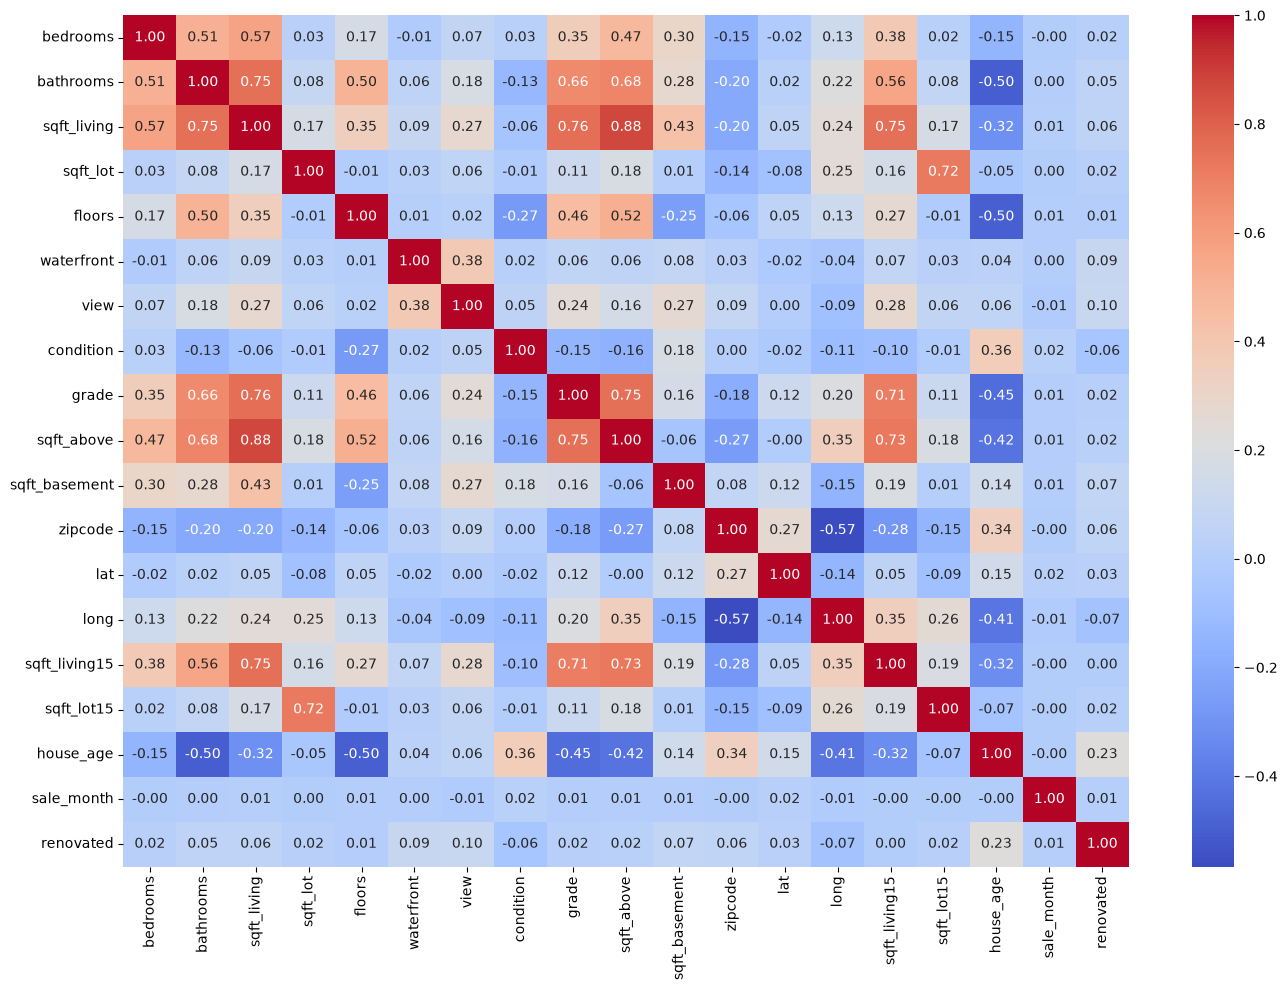

Removed features: ['sqft_above']
Features remaining: 18


In [13]:
plt.figure(figsize=(14, 10))
sns.heatmap(X_train.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.show()

# Drop one feature from each pair with correlation above 0.85.
def correlation(dataset, threshold):
    correlated_columns = set()
    corr_matrix = dataset.corr()
    for column_index in range(len(corr_matrix.columns)):
        for previous_index in range(column_index):
            value = corr_matrix.iloc[column_index, previous_index]
            if abs(value) > threshold:
                correlated_columns.add(corr_matrix.columns[column_index])
    return correlated_columns

corr_features = correlation(X_train, 0.85)
X_train = X_train.drop(columns=corr_features)
X_test = X_test.drop(columns=corr_features)
print(f"Removed features: {sorted(corr_features)}")
print(f"Features remaining: {X_train.shape[1]}")

In [14]:
# Scale using only the training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Ridge MAE: $124,398.96
Ridge RMSE: $211,429.56
Ridge R-squared: 0.701


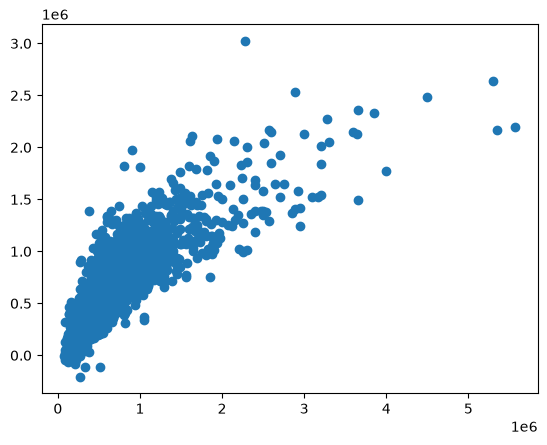

In [15]:
ridge_model = Ridge(alpha=1000)
ridge_model.fit(X_train_scaled, y_train)
ridge_predictions = ridge_model.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)
print(f"Ridge MAE: ${ridge_mae:,.2f}")
print(f"Ridge RMSE: ${ridge_rmse:,.2f}")
print(f"Ridge R-squared: {ridge_r2:.3f}")

plt.scatter(y_test, ridge_predictions)
plt.show()

Lasso MAE: $125,872.81
Lasso RMSE: $210,204.11
Lasso R-squared: 0.705


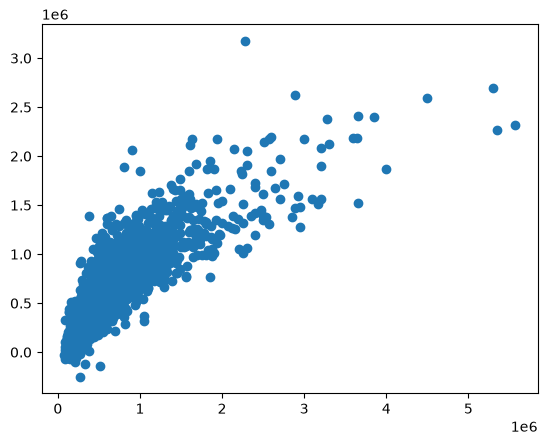

In [16]:
lasso_model = Lasso(alpha=1000, max_iter=50000)
lasso_model.fit(X_train_scaled, y_train)
lasso_predictions = lasso_model.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_r2 = r2_score(y_test, lasso_predictions)
print(f"Lasso MAE: ${lasso_mae:,.2f}")
print(f"Lasso RMSE: ${lasso_rmse:,.2f}")
print(f"Lasso R-squared: {lasso_r2:.3f}")

plt.scatter(y_test, lasso_predictions)
plt.show()

Elastic Net MAE: $124,262.16
Elastic Net RMSE: $217,942.92
Elastic Net R-squared: 0.682


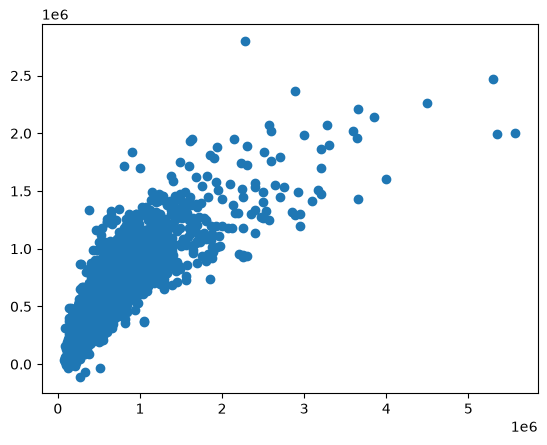

In [17]:
elastic_net_model = ElasticNet(alpha=1, l1_ratio=0.75, max_iter=50000)
elastic_net_model.fit(X_train_scaled, y_train)
elastic_net_predictions = elastic_net_model.predict(X_test_scaled)

elastic_net_mae = mean_absolute_error(y_test, elastic_net_predictions)
elastic_net_rmse = np.sqrt(mean_squared_error(y_test, elastic_net_predictions))
elastic_net_r2 = r2_score(y_test, elastic_net_predictions)
print(f"Elastic Net MAE: ${elastic_net_mae:,.2f}")
print(f"Elastic Net RMSE: ${elastic_net_rmse:,.2f}")
print(f"Elastic Net R-squared: {elastic_net_r2:.3f}")

plt.scatter(y_test, elastic_net_predictions)
plt.show()

In [18]:
comparison = pd.DataFrame(
    {
        "Model": ["Ridge", "Lasso", "Elastic Net"],
        "MAE": [ridge_mae, lasso_mae, elastic_net_mae],
        "RMSE": [ridge_rmse, lasso_rmse, elastic_net_rmse],
        "R-squared": [ridge_r2, lasso_r2, elastic_net_r2],
    }
)
display(comparison.round(3))
print(f"Lowest MAE: {comparison.loc[comparison['MAE'].idxmin(), 'Model']}")

,Model,MAE,RMSE,R-squared
0,Ridge,124398.958,211429.559,0.701
1,Lasso,125872.813,210204.112,0.705
2,Elastic Net,124262.162,217942.923,0.682


Lowest MAE: Elastic Net
